In [2]:
import pandas as pd

# 1. Carregar a base tratada definindo os tipos de dados explícitos para evitar o DtypeWarning
caminho_dados = '../data/processed/online_retail_cleaned.csv'
df = pd.read_csv(
    caminho_dados, 
    dtype={'InvoiceNo': str, 'StockCode': str}
)

# 2. Converter a coluna InvoiceDate para o tipo datetime
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# 3. Manter apenas compras associadas a um ID de cliente válido
df_rfm_base = df[df['CustomerID'].notnull()].copy()
df_rfm_base['CustomerID'] = df_rfm_base['CustomerID'].astype(int)

# 4. Exibir o número de clientes únicos e as primeiras linhas
print(f"Total de registros com ID de cliente: {len(df_rfm_base):,}")
print(f"Total de clientes únicos na base: {df_rfm_base['CustomerID'].nunique():,}")
df_rfm_base.head()

Total de registros com ID de cliente: 397,884
Total de clientes únicos na base: 4,338


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalSales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [3]:
# 1. Definir a data de referência como 1 dia após a última compra registrada na base
data_referencia = df_rfm_base['InvoiceDate'].max() + pd.Timedelta(days=1)

# 2. Agrupar por CustomerID e calcular Recência, Frequência e Valor Monetário
df_rfm = df_rfm_base.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (data_referencia - x.max()).days, # Recência em dias
    'InvoiceNo': 'nunique',                                    # Frequência (pedidos únicos)
    'TotalSales': 'sum'                                        # Valor Monetário (£)
}).reset_index()

# 3. Renomear as colunas para padrão profissional
df_rfm.columns = ['CustomerID', 'Recency', 'Frequency', 'Monetary']

# 4. Exibir as primeiras linhas da tabela RFM
print("=== TABELA RFM POR CLIENTE ===")
print(f"Total de clientes segmentados: {len(df_rfm):,}")
df_rfm.head()

=== TABELA RFM POR CLIENTE ===
Total de clientes segmentados: 4,338


,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,19,1,1757.55
4,12350,310,1,334.40


In [4]:
# 1. Estabelecer a data de referência (1 dia após a transação mais recente da base)
data_referencia = df_rfm_base['InvoiceDate'].max() + pd.Timedelta(days=1)

# 2. Agrupar por cliente e agregar Recência, Frequência e Valor Monetário
df_rfm = df_rfm_base.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (data_referencia - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalSales': 'sum'
}).reset_index()

# 3. Renomear colunas para termos de negócios em inglês/padrão RFM
df_rfm.columns = ['CustomerID', 'Recency', 'Frequency', 'Monetary']

# 4. Exibir o resultado formatado das 5 primeiras linhas e resumo estatístico
print(f"Total de clientes processados para a análise RFM: {len(df_rfm):,}\n")
df_rfm.head()

Total de clientes processados para a análise RFM: 4,338



,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,19,1,1757.55
4,12350,310,1,334.40


In [5]:
# 1. Atribuir notas de 1 a 5 para Recência (R_Score) — Invertido: recência menor = nota maior
df_rfm['R_Score'] = pd.qcut(df_rfm['Recency'], q=5, labels=[5, 4, 3, 2, 1])

# 2. Atribuir notas de 1 a 5 para Frequência (F_Score) 
# Usamos rank(method='first') para evitar erros caso haja muitos clientes com apenas 1 compra
df_rfm['F_Score'] = pd.qcut(df_rfm['Frequency'].rank(method='first'), q=5, labels=[1, 2, 3, 4, 5])

# 3. Atribuir notas de 1 a 5 para Valor Monetário (M_Score)
df_rfm['M_Score'] = pd.qcut(df_rfm['Monetary'], q=5, labels=[1, 2, 3, 4, 5])

# 4. Concatenar as notas para criar a pontuação final (RFM_Score e RFM_Group)
df_rfm['RFM_Group'] = df_rfm['R_Score'].astype(str) + df_rfm['F_Score'].astype(str) + df_rfm['M_Score'].astype(str)
df_rfm['RFM_Score'] = df_rfm[['R_Score', 'F_Score', 'M_Score']].sum(axis=1)

# 5. Visualizar o resultado das pontuações
print("=== TABELA RFM COM PONTUAÇÕES E CLASSIFICAÇÃO ===")
df_rfm.head()

=== TABELA RFM COM PONTUAÇÕES E CLASSIFICAÇÃO ===


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Group,RFM_Score
0,12346,326,1,77183.60,1,1,5,115,7
1,12347,2,7,4310.00,5,5,5,555,15
2,12348,75,4,1797.24,2,4,4,244,10
3,12349,19,1,1757.55,4,1,4,414,9
4,12350,310,1,334.40,1,1,2,112,4


In [6]:
# 1. Função para mapear R_Score e F_Score em nomes de segmentos de mercado
def mapear_segmento(df):
    r = int(df['R_Score'])
    f = int(df['F_Score'])
    
    if r >= 4 and f >= 4:
        return 'Champions'
    elif r >= 3 and f >= 3:
        return 'Loyal Customers'
    elif r >= 4 and f <= 2:
        return 'Promising / New'
    elif r == 3 and f <= 2:
        return 'Potential Loyalists'
    elif r == 2 and f >= 3:
        return 'At Risk'
    elif r <= 2 and f <= 2:
        return 'Hibernating / Lost'
    else:
        return 'Need Attention'

# 2. Aplicar a função para criar a coluna Segment
df_rfm['Segment'] = df_rfm.apply(mapear_segmento, axis=1)

# 3. Exibir a distribuição de clientes por segmento
resumo_segmentos = df_rfm['Segment'].value_counts().reset_index()
resumo_segmentos.columns = ['Segmento', 'Qtd_Clientes']
resumo_segmentos['%_Clientes'] = (resumo_segmentos['Qtd_Clientes'] / len(df_rfm)) * 100

print("=== DISTRIBUIÇÃO DA BASE POR SEGMENTO RFM ===")
print(resumo_segmentos.to_string(formatters={'%_Clientes': '{:.2f}%'.format}))

=== DISTRIBUIÇÃO DA BASE POR SEGMENTO RFM ===
              Segmento  Qtd_Clientes %_Clientes
0            Champions          1139     26.26%
1   Hibernating / Lost          1065     24.55%
2      Loyal Customers           821     18.93%
3              At Risk           442     10.19%
4  Potential Loyalists           351      8.09%
5      Promising / New           319      7.35%
6       Need Attention           201      4.63%


In [7]:
# 1. Definir o caminho de destino na pasta data/processed/
caminho_saida_rfm = '../data/processed/rfm_clientes_segmentados.csv'

# 2. Exportar o DataFrame df_rfm para CSV
df_rfm.to_csv(caminho_saida_rfm, index=False, encoding='utf-8')

print("Tabela RFM de clientes exportada com sucesso para:")
print(caminho_saida_rfm)

Tabela RFM de clientes exportada com sucesso para:
../data/processed/rfm_clientes_segmentados.csv


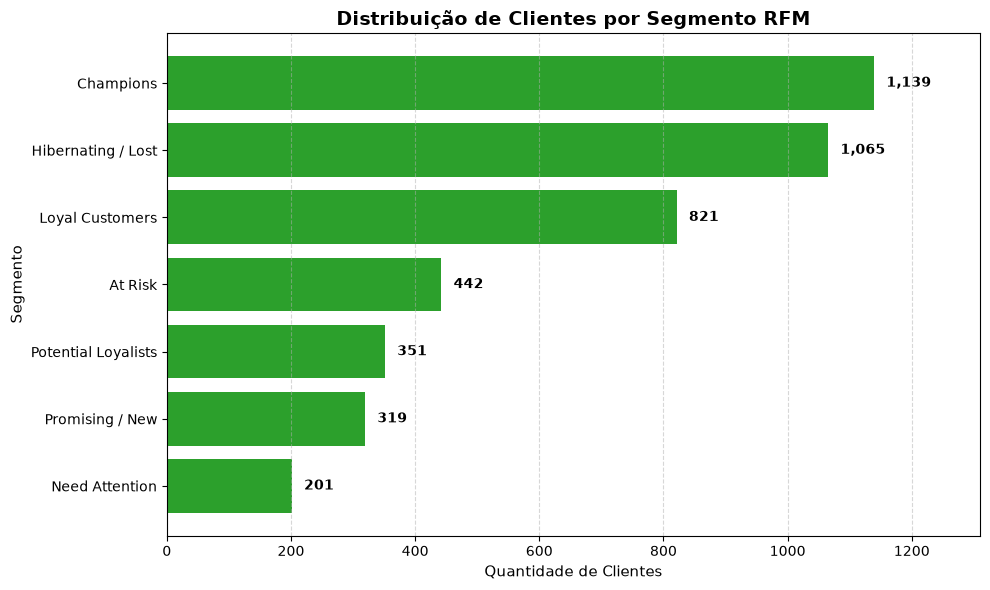

In [8]:
import matplotlib.pyplot as plt

# 1. Contar e ordenar a quantidade de clientes por segmento
contagem_segmentos = df_rfm['Segment'].value_counts().sort_values(ascending=True)

# 2. Configurar a figura do gráfico
plt.figure(figsize=(10, 6))
barras = plt.barh(contagem_segmentos.index, contagem_segmentos.values, color='#2ca02c')

# 3. Adicionar rótulos com a contagem exata em cada barra
for bar in barras:
    width = bar.get_width()
    plt.text(width + 20, bar.get_y() + bar.get_height()/2, f'{int(width):,}', 
             va='center', ha='left', fontsize=10, fontweight='bold')

# 4. Títulos e formatação
plt.title('Distribuição de Clientes por Segmento RFM', fontsize=14, fontweight='bold')
plt.xlabel('Quantidade de Clientes', fontsize=11)
plt.ylabel('Segmento', fontsize=11)
plt.xlim(0, max(contagem_segmentos.values) * 1.15)  # Espaço extra para o texto das barras
plt.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()